In [1]:
%pip install -q requests pydantic python-dotenv pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
%load_ext autoreload
%autoreload 2

import os, re, sys, json, time, ast, operator, subprocess
from pathlib import Path
from dataclasses import dataclass, field
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field, ValidationError

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("OPENROUTER_API_KEY", UserSecretsClient().get_secret("OPENROUTER_API_KEY"))
except Exception:
    pass
assert os.getenv("OPENROUTER_API_KEY"), "нет ключа: положите его в .env рядом с ноутбуком или в Kaggle Secrets"

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}",
           "HTTP-Referer": "https://postypashki.ru", "X-Title": "ReAct_agent"}
MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = next((p for p in [Path("qa_data"), Path("/kaggle/input/datasets/artmakar04/"), Path("/kaggle/input/seminar01-data/data")]
             if (p / "compare_10.jsonl").exists()), Path("qa-data"))
TRACES, IMG = Path("traces"), Path("img")
TRACES.mkdir(exist_ok=True)
IMG.mkdir(exist_ok=True)

## 1. Ledger and chat methods

In [3]:
@dataclass
class Ledger:
    calls: list = field(default_factory=list)

    def add(self, tag, model, usage, seconds=0.0):
        p, c = usage.get("prompt_tokens", 0), usage.get("completion_tokens", 0)
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": p, "completion": c,
                           "cost": cost, "seconds": round(seconds, 2)})
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    def table(self):
        df = pd.DataFrame(self.calls)
        return df.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                completion=("completion", "sum"), cost=("cost", "sum"),
                                                seconds=("seconds", "sum")).round(5)

ledger = Ledger()

In [4]:
def post_with_retry(body, attempts=3):
    for attempt in range(attempts , ):
        r = requests.post(CHAT_URL , json = body , headers = HEADERS , timeout = 120)
        if r.status_code == 200:
            return r.json()
        elif r.status_code in (429 , 500 , 502 , 503) and attempt < attempts - 1:
            time.sleep(1.5 * (attempt + 1))
            continue
        raise RuntimeError(f"HTTP {r.status_code} : {r.text[:300]}")

In [5]:
def chat(messages, model, tools=None, tag="chat", temperature=None):
    body = {"model": model, "messages": messages, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
        body["tool_choice"] = "auto"
    if temperature is not None:
        body["temperature"] = temperature
    started = time.perf_counter()
    data = post_with_retry(body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]

In [6]:
question = [{"role": "user", "content": "Объясни в трёх предложениях, что такое контекстное окно языковой модели. Включи максимально подробное объяснение"}]
answers = {name: chat(question, model, tag="window")["content"] for name, model in MODELS.items()}
ledger.table().loc["window"]

,calls,prompt,completion,cost,seconds
model,,,,,
claude-haiku-4.5,1,48,223,0.00116,2.90
claude-sonnet-4.6,1,48,398,0.00611,9.37
gpt-4o-mini,1,35,122,0.00008,2.78


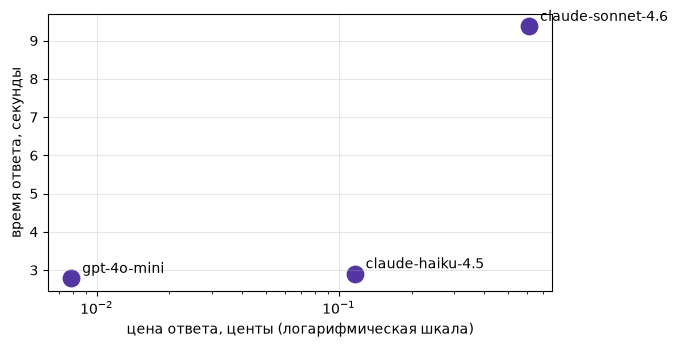

In [7]:
def cost_time_chart(tag):
    df = pd.DataFrame([c for c in ledger.calls if c["tag"] == tag])
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.scatter(df["cost"] * 100, df["seconds"], s=140, color=COLORS["violet"])
    for _, r in df.iterrows():
        ax.annotate(r["model"], (r["cost"] * 100, r["seconds"]), xytext=(8, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("цена ответа, центы (логарифмическая шкала)")
    ax.set_ylabel("время ответа, секунды")
    ax.grid(alpha=0.3)
    return fig

cost_time_chart("window");

In [8]:
for name, text in answers.items():
    print(f"{name:7s}| {text[:230]}")

cheap  | Контекстное окно языковой модели — это ограниченное количество слов или токенов, которые модель может обрабатывать одновременно для генерации текста или предсказания следующего слова. Именно в пределах этого окна модель учитывает 
mid    | # Контекстное окно языковой модели

Контекстное окно — это максимальный объём текста (измеряемый в токенах, которые представляют слова или части слов), который модель может одновременно обработать и учитывать при генерации ответа.
strong | ## Контекстное окно языковой модели

**Контекстное окно** — это максимальное количество токенов (слов, частей слов, символов пунктуации), которые языковая модель может одновременно «видеть» и учитывать при генерации ответа, включа


## 2. Ответ по схеме и температура

Модель просят вернуть JSON по схеме Pydantic-модели `Answer`. Схема уходит в системный промпт, ответ проверяется той же моделью. Если ответ не прошёл проверку, текст ошибки возвращается модели, и она пробует снова. Этот приём, ошибка обратно модели как текст, дальше держит весь цикл агента.

`json_from` вытаскивает первый объект из текста и разбирает его терпимо к переносам строк внутри значений: модели любят оборачивать JSON словами и писать рассуждение в несколько строк.

Две демонстрации после дырки. Схема `Numeric` требует число, а вопрос про столицу Франции: смотрим, сколько вызовов уйдёт и чем кончится. И одна и та же просьба придумать название кофейни пять раз при температуре 0 и пять раз при 1.2.

In [9]:
class Answer(BaseModel):
    reasoning: str = Field(description="ход решения в два-три предложения")
    final: str = Field(description="только итоговый ответ: число или короткая фраза")

SCHEMA_PROMPT = "Отвечай строго одним JSON-объектом по этой схеме, без текста вокруг, строки в одну линию, без лишних отступов, \t, \n:\n{schema}"

def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S)
    if not m:
        raise ValueError("в ответе нет JSON")
    return json.loads(m.group(0), strict=False)

In [10]:
Answer.model_json_schema()

{'properties': {'reasoning': {'description': 'ход решения в два-три предложения',
   'title': 'Reasoning',
   'type': 'string'},
  'final': {'description': 'только итоговый ответ: число или короткая фраза',
   'title': 'Final',
   'type': 'string'}},
 'required': ['reasoning', 'final'],
 'title': 'Answer',
 'type': 'object'}

In [11]:
schema=Answer
SCHEMA_PROMPT.format(schema=json.dumps(schema.model_json_schema(), ensure_ascii=False))

'Отвечай строго одним JSON-объектом по этой схеме, без текста вокруг, строки в одну линию, без лишних отступов, \t, \n:\n{"properties": {"reasoning": {"description": "ход решения в два-три предложения", "title": "Reasoning", "type": "string"}, "final": {"description": "только итоговый ответ: число или короткая фраза", "title": "Final", "type": "string"}}, "required": ["reasoning", "final"], "title": "Answer", "type": "object"}'

In [12]:
def ask_structured(question, model, schema=Answer, attempts=3):
    messages = [
        {"role": "system", "content": SCHEMA_PROMPT.format(schema=json.dumps(schema.model_json_schema(), ensure_ascii=False))},
        {"role": "user", "content": question}
    ]
    for _ in range(attempts):
        msg = chat(messages, model, tag="struct")
        try:
            return schema.model_validate(json_from(msg["content"]))
        except (ValidationError, ValueError) as e:
            messages += [msg, {"role": "user", "content": f"Ответ не прошел проверку на структуру: {e}. Верни ответ по строгой JSON схеме"}]
    raise ValueError("Модель не справилась")

In [13]:
def load_tasks(name):
    return [json.loads(line) for line in Path(name).read_text(encoding="utf-8").splitlines() if line.strip()]

task = load_tasks("data/fresh.jsonl")[0]
ans = ask_structured(task["question"], MODELS["cheap"])
ans, task["answer"]

(Answer(reasoning="Ukraine announced its decision to boycott the closing ceremony of the 2026 Winter Paralympics due to ongoing geopolitical tensions and concerns over security. The boycott reflects Ukraine's stance on international events amid the current conflict.", final='March 2026'),
 '15 March')

**Numeric type**

In [14]:
class Numeric(BaseModel):
    final: float = Field(description="ответ числом")

calls_before = len(ledger.calls)
try:
    result = ask_structured("Какой год основания франции", MODELS["cheap"], Numeric)
except ValueError as e:
    result = e
print("вызовов потрачено:", len(ledger.calls) - calls_before, "| результат:", result)

вызовов потрачено: 1 | результат: final=843.0


In [15]:
prompt = [{"role": "user", "content": "Придумай название для кофейни рядом с университетом. Только название, два слова."}]
pd.DataFrame({f"temperature {t}": [chat(prompt, MODELS["cheap"], tag="temperature", temperature=t)["content"] for _ in range(5)]
              for t in (0.0, 1.2)})

,temperature 0.0,temperature 1.2
0,Кофейный Уголок,Кофейный Уголок
1,Кофейный Уголок,Кофейный уголок
2,Кофейный Уголок,Кофейный Уголок.
3,Кофейный Уголок,Кофе Ума
4,Кофейный Уголок,Кофейный Уголок


## 3. Проверка моделей

In [41]:
# Проверка ответа. Более гибкая проверка в доработку к сему
NUM_WORDS = {w: str(i) for i, ws in enumerate([
    [], ["one", "один", "одна", "одно"], ["two", "два", "две"], ["three", "три"], ["four", "четыре"],
    ["five", "пять"], ["six", "шесть"], ["seven", "семь"], ["eight", "восемь"], ["nine", "девять"],
    ["ten", "десять"], ["eleven"], ["twelve"], ["thirteen"], ["fourteen"], ["fifteen"],
    ["sixteen"], ["seventeen"], ["eighteen"], ["nineteen"], ["twenty"]]) for w in ws}
MONTHS = [(1, "january|jan|январ"), (2, "february|feb|феврал"), (3, "march|mar|март"), (4, "april|apr|апрел"),
          (5, "may|ма[йя]"), (6, "june|jun|июн"), (7, "july|jul|июл"), (8, "august|aug|август"),
          (9, "september|sept|sep|сентябр"), (10, "october|oct|октябр"), (11, "november|nov|ноябр"),
          (12, "december|dec|декабр")]

def normalize(text):
    text = str(text).lower().replace("ё", "е").replace(",", "")
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(NUM_WORDS.get(w, w) for w in text.split())

def day_months(text):
    """Все даты вида «15 March», «March 15», «15 марта» как пары (день, месяц)."""
    t, out = str(text).lower().replace("ё", "е"), set()
    for month, alt in MONTHS:
        out |= {(int(d), month) for d in re.findall(rf"\b(\d{{1,2}})\s+(?:{alt})\w*", t)}
        out |= {(int(d), month) for d in re.findall(rf"\b(?:{alt})\w*\.?\s+(\d{{1,2}})\b", t)}
    return out

def is_correct(task, answer):
    if task["source"] == "gsm8k":
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(answer).replace(",", ""))
        return bool(nums) and abs(float(nums[-1]) - float(task["answer"])) < 1e-6
    gold_dates = day_months(task["answer"])
    if gold_dates:                       # эталон — дата: сравниваем день и месяц, а не запись
        return bool(gold_dates & day_months(answer))
    return normalize(task["answer"]) in normalize(answer)

def summary(config, model, n, correct, cost, steps, seconds=0.0):
    return {"config": config, "model": model.split("/")[-1], "n": n, "accuracy": round(correct / n, 2),
            "cost_per_task": round(cost / n, 5), "cost_per_correct": round(cost / correct, 5) if correct else float("inf"),
            "avg_steps": round(steps, 2), "avg_seconds": round(seconds, 1)}

def compare_models(tasks, models):
    rows = []
    for name, model in models.items():
        before, correct, started = ledger.total, 0, time.perf_counter()
        for task in tasks:
            try:
                correct += is_correct(task, ask_structured(task["question"], model).final)
            except Exception:
                pass
        rows.append(summary("без инструментов, JSON", model, len(tasks), correct, ledger.total - before, 1,
                            (time.perf_counter() - started) / len(tasks)))
    return pd.DataFrame(rows)

def compare_chart(df):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
    axes[0].bar(df["model"], df["accuracy"] * 100, color=COLORS["violet"])
    axes[0].set_ylabel("доля верных, %")
    axes[0].set_ylim(0, 105)
    axes[1].bar(df["model"], df["cost_per_correct"] * 100, color=COLORS["amber"])
    axes[1].set_ylabel("цена верного ответа, центы")
    axes[2].bar(df["model"], df["avg_seconds"], color=COLORS["teal"])
    axes[2].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.tick_params(axis="x", labelrotation=12)
        ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    return fig

## 4. ReAct Agent

**Регистр тулзов**

In [17]:
TOOLS = {}

def register(fn, args_model: type[BaseModel], description: str):   
    TOOLS[fn.__name__] = {
        "fn": fn,
        "args": args_model,
        "schema": {
            "type": "function",
            "function": {                                           
                "name": fn.__name__,                                
                "description": description,
                "parameters": args_model.model_json_schema(),       
            },
        },
    }

In [18]:
from tools import calculator, python_exec, web_search, page_find, DESCRIPTIONS, ARGS

for fn in [calculator, python_exec, web_search, page_find]:
    register(fn, ARGS[fn.__name__], DESCRIPTIONS[fn.__name__])

list(TOOLS)

['calculator', 'python_exec', 'web_search', 'page_find']

In [32]:
SYSTEM = ("Сегодня 2 ноября 2026 года. События 2025 и 2026 годов уже произошли, информация о них есть в Википедии: "
          "не отказывайся отвечать, а ищи. Если нужно посчитать или найти факт, вызывай инструменты, а не угадывай. "
          "Если вступление статьи не содержит ответа, читай статью через page_find; факты о событиях часто лежат "
          "в обзорных статьях вроде '2026 in Ukraine' или в таблицах страницы турнира. "
          "Когда ответ готов, напиши его последней строкой в формате FINAL: <ответ>. "
          "Для числовых задач в FINAL только число, для вопросов о фактах короткая фраза на языке вопроса; "
          "имена и названия пиши в именительном падеже, как в источнике.")
@dataclass
class Run:
    question: str
    answer: str
    steps: int
    messages: list
    cost: float = 0.0
    seconds: float = 0.0


def looped(seen, calls):
    keys = [(c["function"]["name"], c["function"]["arguments"]) for c in calls]
    repeated = any(k in seen for k in keys)
    seen.update(keys)
    
    return repeated

def finish (model , messages , step):
    del messages[-1]
    messages.append({"role" : "user" , "content" : "Инструменты больше недоступны. Ответь по тому , что уже известно , последней строкой FINAL: <ответ> ."})
    msg = chat(messages , model , tag = 'agent')
    messages.append(msg)
    return msg.get("content") or "" , step + 1



In [20]:
def run_tool(call):
    name = call["function"]["name"]

    try:
        spec = TOOLS[name]
        args = spec["args"].model_validate_json(call["function"]["arguments"])
        result = spec["fn"](**args.model_dump())
    except Exception as e:
        result = f"НЕ удалось вызвать инструмент {name}: {e}"
    return {"role": "tool", "tool_call_id" : call["id"], "content": str(result)[:2000]}

In [21]:
def agent_loop(messages, model, tool_names, max_steps):
    seen = set()
    for step in range(1, max_steps + 1):
        msg = chat(messages, model, tools=[TOOLS[n]["schema"] for n in tool_names] or None, tag='agent')
        messages.append(msg)
        calls = msg.get("tool_calls") or []

        if not calls:
            return msg.get("content") or "", step
        if looped(seen, calls) or step == max_steps:
            return finish(model, messages, step)

        messages += [run_tool(c) for c in calls]

In [22]:
def agent(question, model, tool_names, max_steps=8):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    before, started = ledger.total, time.perf_counter()
    answer, steps = agent_loop(messages, model, tool_names, max_steps)
    return Run(question, answer, steps, messages, ledger.total - before, time.perf_counter() - started)

def show_trace(run):
    for m in run.messages[1:]:
        calls = "; ".join(f"{c['function']['name']}{c['function']['arguments']}" for c in m.get("tool_calls") or [])
        text = " ".join((m.get("content") or "").split())[:180]
        print(f"{m['role']:9s}| {text} {calls}")
    print(f"шагов: {run.steps}, цена: {run.cost * 100:.3f} ¢, время: {run.seconds:.1f} c")

In [23]:
run = agent("Сколько будет 17 * 23 + 5? Посчитай инструментом.", MODELS["cheap"], ["calculator"])
show_trace(run)

user     | Сколько будет 17 * 23 + 5? Посчитай инструментом. 
assistant|  calculator{"expr":"17*23+5"}
tool     | 396 
assistant| FINAL: 396 
шагов: 2, цена: 0.007 ¢, время: 1.9 c


In [24]:
run = agent("Посчитай площадь круга радиусом 3 (пи возьми 3.14159) и объём куба со стороной 4. Верни оба числа.", MODELS["cheap"], ["calculator"])
show_trace(run)
[len(m.get("tool_calls") or []) for m in run.messages if m["role"] == "assistant"]

user     | Посчитай площадь круга радиусом 3 (пи возьми 3.14159) и объём куба со стороной 4. Верни оба числа. 
assistant|  calculator{"expr": "3.14159 * (3 ** 2)"}; calculator{"expr": "4 ** 3"}
tool     | 28.2743 
tool     | 64 
assistant| FINAL: 28.2743, 64 
шагов: 2, цена: 0.011 ¢, время: 2.4 c


[2, 0]

In [25]:
class BrokenArgs(BaseModel):
    query: str = Field(description="любой запрос")

def broken_search(query: str) -> str:
    return "ошибка: сервис недоступен, попробуйте ещё раз"

register(broken_search, BrokenArgs, "Ищет ответ на любой вопрос в интернете")
run = agent("Кто написал роман «Мы»? Обязательно проверь через broken_search.", MODELS["cheap"], ["broken_search"], max_steps=8)
show_trace(run)

user     | Кто написал роман «Мы»? Обязательно проверь через broken_search. 
assistant|  broken_search{"query":"автор романа Мы"}
tool     | ошибка: сервис недоступен, попробуйте ещё раз 
user     | Инструменты больше недоступны. Ответь по тому , что уже известно , последней строкой FINAL: <ответ> . 
assistant| Роман «Мы» написал Евгений Замятин. FINAL: Евгений Замятин 
шагов: 3, цена: 0.011 ¢, время: 3.3 c


In [26]:
def flaky_search(query: str) -> str:
    return "ошибка: сервис перегружен, переформулируйте запрос и попробуйте снова"

register(flaky_search, BrokenArgs, "Ищет ответ на любой вопрос в интернете")
run_flaky = agent("Кто написал роман «Мы»? Обязательно проверь через flaky_search, пока не получишь результат.", MODELS["cheap"], ["flaky_search"], max_steps=8)
show_trace(run_flaky)

user     | Кто написал роман «Мы»? Обязательно проверь через flaky_search, пока не получишь результат. 
assistant|  flaky_search{"query":"роман Мы автор"}
tool     | ошибка: сервис перегружен, переформулируйте запрос и попробуйте снова 
assistant|  flaky_search{"query":"кто написал роман Мы"}
tool     | ошибка: сервис перегружен, переформулируйте запрос и попробуйте снова 
assistant|  flaky_search{"query":"автор романа Мы"}
tool     | ошибка: сервис перегружен, переформулируйте запрос и попробуйте снова 
assistant|  flaky_search{"query":"роман Мы кто автор"}
tool     | ошибка: сервис перегружен, переформулируйте запрос и попробуйте снова 
assistant| Не удалось получить информацию из источников. Однако, роман «Мы» написал Евгений Замятин. FINAL: Евгений Замятин 
шагов: 5, цена: 0.024 ¢, время: 5.6 c


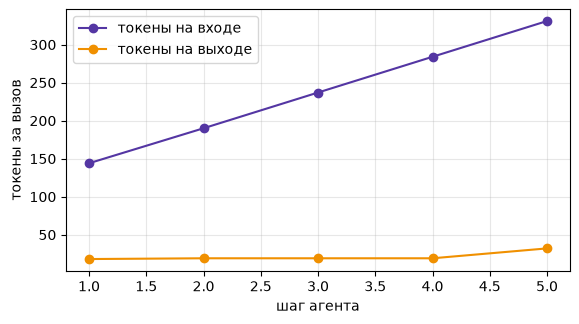

In [27]:
def context_chart(run):
    calls = [c for c in ledger.calls if c["tag"] == "agent"][-run.steps:]
    steps = range(1, len(calls) + 1)
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.plot(steps, [c["prompt"] for c in calls], marker="o", color=COLORS["violet"], label="токены на входе")
    ax.plot(steps, [c["completion"] for c in calls], marker="o", color=COLORS["amber"], label="токены на выходе")
    ax.set_xlabel("шаг агента")
    ax.set_ylabel("токены за вызов")
    ax.legend()
    ax.grid(alpha=0.3)
    return fig

context_chart(run_flaky);

## 5. Инструменты

In [29]:
# Живая проверка поиска и чтения страницы на русской Википедии
print(web_search("Чемпионат мира по футболу 2026", lang="ru")[:300])
print()
print(page_find("Чемпионат мира по футболу 2026", ["финал", "Испания", "Аргентина"], lang="ru"))

[Чемпионат мира по футболу 2026] Чемпионат мира по футболу 2026 года (англ. 2026 FIFA World Cup) — 23-й чемпионат мира по футболу ФИФА, финальная часть которого прошла с 11 июня по 19 июля 2026 года. Изначально в финальном этапе чемпионата должны были участвовать, как обычно, 32 сборные, но 10 январ

[Чемпионат мира по футболу 2026] найдено строк: 8
Групповой этап турнира выглядел так: 12 групп по 4 команды в каждой; в плей-офф вышли команды, занявшие 1-е и 2-е места, а также 8 лучших команд, занявших 3-е место. Также появилась новая стадия в плей-офф — 1/16 финала.
Чемпионский титул завоевала сборная Испании, обыгравшая в финале действующего чемпиона — сборную Аргентины. За турнир команда пропустила лишь 1 гол (в четвертьфинале), что стало рекордом среди сборных, занимавших первые четыре места на чемпионатах мира.
Выбор хозяина
Страна
…
19 июля 202615:00 UTC−4
Испания | 1:0 (доп. вр.) | Аргентина
Торрес 106′
(отчёт)
…
Аймен Хусейн (в матче группового этапа против Норвегии)
Дини (в мат

## 6. Прогоны ,   трейсы , деньги 

In [30]:
def final_answer(text):
    m = re.search(r"FINAL:\s*(.+)", text or "")
    return m.group(1).strip() if m else (text or "").strip()

def run_tasks(tasks, model, tool_names, config):
    folder = TRACES / config / model.split("/")[-1]
    folder.mkdir(parents=True, exist_ok=True)
    rows = []
    for task in tasks:
        try:
            run = agent(task["question"], model, tool_names)
        except Exception as e:
            run = Run(task["question"], f"ошибка: {e}", 0, [])
        ok = is_correct(task, final_answer(run.answer))
        rows.append({"config": config, "model": model.split("/")[-1], "id": task["id"], "source": task["source"],
                     "correct": ok, "steps": run.steps, "tool_calls": sum(m["role"] == "tool" for m in run.messages),
                     "cost": run.cost, "seconds": round(run.seconds, 1), "answer": final_answer(run.answer)[:60], "gold": task["answer"]})
        (folder / f"{task['id']}.json").write_text(json.dumps({"task": task, "answer": run.answer, "correct": ok, "cost": run.cost,
                                                              "messages": run.messages}, ensure_ascii=False, indent=1), encoding="utf-8")
    return pd.DataFrame(rows)

def report(results):
    rows = [summary(config, model, len(df), int(df["correct"].sum()), df["cost"].sum(), df["steps"].mean(), df["seconds"].mean())
            for (config, model), df in results.groupby(["config", "model"])]
    return pd.DataFrame(rows).sort_values("cost_per_task").reset_index(drop=True)

def money_chart(table, path="img/money_quality.png"):
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, r in table.iterrows():
        color = COLORS["red"] if "каскад" in r["config"] else COLORS["amber"] if "sonnet" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100),
                    fontsize=8, xytext=(6, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("цена задачи, центы (логарифмическая шкала)")
    ax.set_ylabel("доля верных ответов, %")
    ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

def steps_chart(results):
    g = results.groupby("config").agg(steps=("steps", "mean"), tool_calls=("tool_calls", "mean"), seconds=("seconds", "mean"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    g[["steps", "tool_calls"]].plot.bar(ax=axes[0], color=[COLORS["violet"], COLORS["teal"]], rot=12)
    axes[0].set_ylabel("в среднем на задачу")
    g["seconds"].plot.bar(ax=axes[1], color=COLORS["amber"], rot=12)
    axes[1].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.grid(alpha=0.3, axis="y")
        ax.set_xlabel("")
    fig.tight_layout()
    return fig

CONFIGS = {"без инструментов": [],
           "поиск": ["web_search"],
           "поиск + чтение": ["web_search", "page_find", "calculator", "python_exec"]}

In [33]:
fresh = load_tasks("data/fresh.jsonl")
by_id = {t["id"]: t for t in fresh}
sample = [by_id[i] for i in ["wc-0", "wc-12", "wc-17", "fresh-0", "fresh-9", "fresh-16"]]   

frames = [
    run_tasks(sample, MODELS["strong"], CONFIGS["без инструментов"], "без инструментов"),
    run_tasks(sample, MODELS["cheap"],  CONFIGS["без инструментов"], "без инструментов"),
    run_tasks(sample, MODELS["cheap"],  CONFIGS["поиск"],            "поиск"),
    run_tasks(sample, MODELS["cheap"],  CONFIGS["поиск + чтение"],   "поиск + чтение"),
    run_tasks(sample, MODELS["mid"],    CONFIGS["поиск + чтение"],   "поиск + чтение"),
]
results = pd.concat(frames, ignore_index=True)
results[["config", "model", "id", "correct", "steps", "tool_calls", "cost", "seconds", "answer", "gold"]]

,config,model,id,correct,steps,tool_calls,cost,seconds,answer,gold
0,без инструментов,claude-sonnet-4.6,wc-0,False,1,0,0.010443,11.7,Педри,Торрес
1,без инструментов,claude-sonnet-4.6,wc-12,False,1,0,0.005721,7.1,Эмилиано Мартинес,Унаи Симон
2,без инструментов,claude-sonnet-4.6,wc-17,False,1,0,0.024789,25.9,Салех Марзук,Омар Артан
3,без инструментов,claude-sonnet-4.6,fresh-0,False,1,0,0.006858,8.0,15 марта 2026 года,15 March
4,без инструментов,claude-sonnet-4.6,fresh-9,False,1,0,0.009297,8.4,Birmingham,New Delhi
5,без инструментов,claude-sonnet-4.6,fresh-16,False,1,0,0.009426,11.0,New York,Montreal Victoire
6,без инструментов,gpt-4o-mini,wc-0,False,1,0,0.000069,2.3,Я не имею возможности проверить информацию пос...,Торрес
7,без инструментов,gpt-4o-mini,wc-12,False,1,0,0.000055,2.6,информация недоступна.,Унаи Симон
8,без инструментов,gpt-4o-mini,wc-17,False,1,0,0.000066,2.1,Мохамед Кара,Омар Артан
9,без инструментов,gpt-4o-mini,fresh-0,False,1,0,0.000049,1.2,I'll look for the relevant information about U...,15 March


In [34]:
table = report(results)
table

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,без инструментов,gpt-4o-mini,6,0.00,0.00006,inf,1.00,1.8
1,поиск + чтение,gpt-4o-mini,6,0.67,0.00085,0.00127,4.33,10.3
2,поиск,gpt-4o-mini,6,0.33,0.00107,0.00322,6.00,18.0
3,без инструментов,claude-sonnet-4.6,6,0.00,0.01109,inf,1.00,12.0
4,поиск + чтение,claude-haiku-4.5,6,1.00,0.02869,0.02869,4.83,13.7


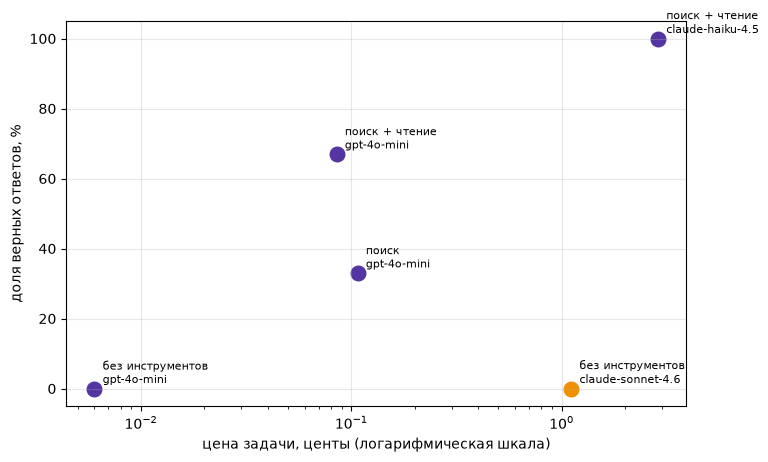

In [35]:
money_chart(table);

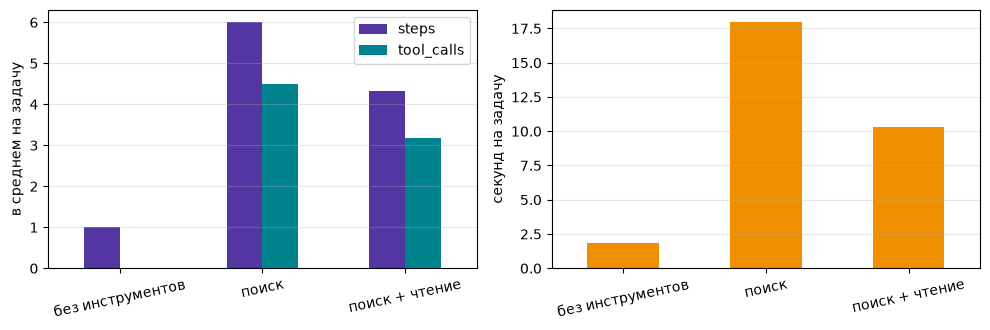

In [36]:
steps_chart(results[results["model"] == "gpt-4o-mini"]);

## 7. Итоговый прогон

In [42]:
fresh = load_tasks("data/fresh.jsonl")
final = [t for t in fresh if t["source"] == "manual"] + [t for t in fresh if t["source"] == "fresh"][:40]
assert len(final) == 60

RUNS = [("strong", "без инструментов"),      
        ("cheap",  "без инструментов"),     
        ("cheap",  "поиск"),                 
        ("cheap",  "поиск + чтение"),        
        ("mid",    "поиск + чтение")]        

start, frames = ledger.total, []
for name, cfg in RUNS:
    frames.append(run_tasks(final, MODELS[name], CONFIGS[cfg], cfg))
    print(f"{cfg:18s} {MODELS[name]:30s} потрачено всего ${ledger.total - start:.2f}")
    if ledger.total - start > 5:
        print("Больше $5: стоп, смотрим трейсы")
        break

final_results = pd.concat(frames, ignore_index=True)
final_results.to_csv("results_raw.csv", index=False)
final_table = report(final_results)
Path("results.md").write_text(final_table.to_string(index=False), encoding="utf-8")
final_table


без инструментов   anthropic/claude-sonnet-4.6    потрачено всего $0.77
без инструментов   openai/gpt-4o-mini             потрачено всего $0.77
поиск              openai/gpt-4o-mini             потрачено всего $0.84
поиск + чтение     openai/gpt-4o-mini             потрачено всего $0.89
поиск + чтение     anthropic/claude-haiku-4.5     потрачено всего $2.59


,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,без инструментов,gpt-4o-mini,60,0.02,0.00006,0.00363,1.00,2.6
1,поиск + чтение,gpt-4o-mini,60,0.58,0.00084,0.00144,4.82,15.7
2,поиск,gpt-4o-mini,60,0.15,0.00111,0.00741,6.82,26.0
3,без инструментов,claude-sonnet-4.6,60,0.08,0.01278,0.15332,1.00,13.4
4,поиск + чтение,claude-haiku-4.5,60,0.62,0.02831,0.04591,4.92,17.5


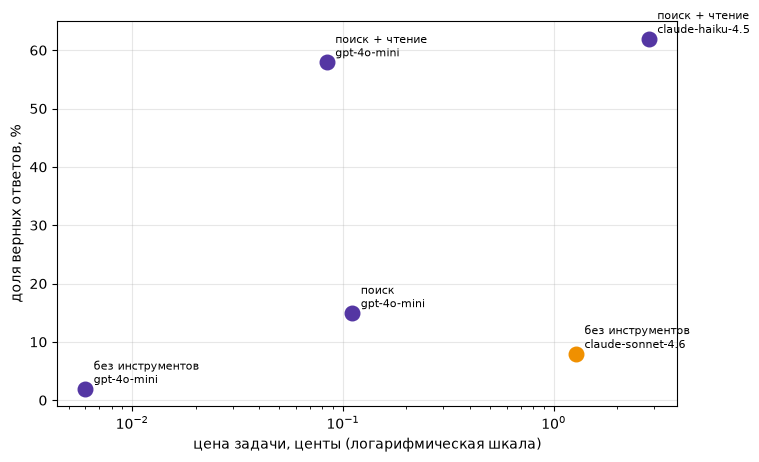

In [43]:
money_chart(final_table, "img/money_quality.png");

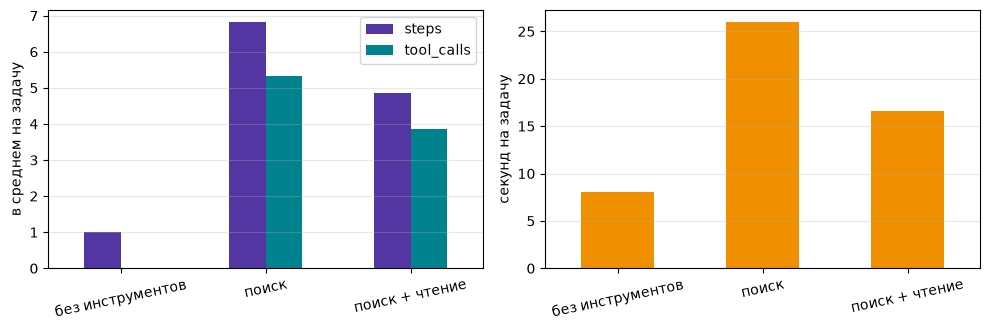

In [44]:
steps_chart(final_results);